# Chapter 7: k-Means

In [1]:
%matplotlib inline
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from scipy.stats import mode
from sklearn.datasets import make_blobs
from sklearn.datasets import load_digits
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import silhouette_score

# On Windows, scikit-learn can warn about a memory leak in KMeans. This is harmless for our small datasets.
warnings.filterwarnings('ignore', message='KMeans is known to have a memory leak')

## 7.1 Introduction & Motivation

Welcome to the unsupervised learning part of this course! If you're reading this, you've made it through all the supervised learning chapters of Data Science Fundamentals. Congratulations!

Now, let's dive into our first unsupervised learning problem: **clustering**. Until now, we've worked with datasets that had both independent variables (the features) and a dependent variable (the target). We built models that predict the value of the dependent variable from the independent variables. This was relatively easy, because the correct answers were always available in our training set.

In unsupervised learning, we don't have this luxury. We only have the independent variables and must find patterns in them on our own. In this chapter, we'll focus on one specific type of pattern: groups (or **clusters**) of observations that resemble each other.

As they say, a picture is worth a thousand words:

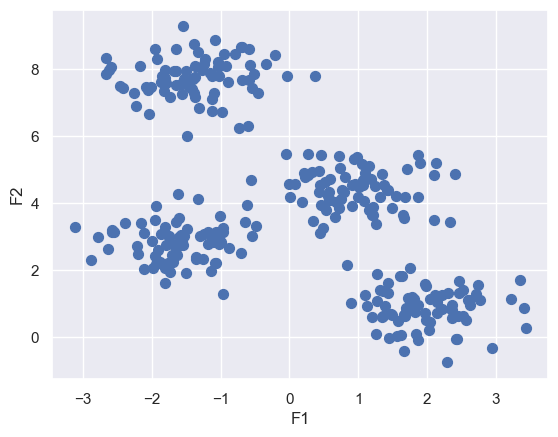

In [2]:
# Create a toy dataset of 300 points spread over 4 groups
# make_blobs also returns the true group of every point (y_true), but we won't use it: we only look at X
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

plt.scatter(X[:, 0], X[:, 1], s=50)
plt.xlabel('F1')
plt.ylabel('F2')
plt.show()

Even though none of the points has a label, we can clearly see a pattern: there are 4 distinct groups of points. The goal of cluster analysis is to find such natural groupings automatically, and to determine which group a new observation belongs to.

**Comparison with supervised learning**: in classification, the classes are known in advance and every training observation comes with its class. In clustering, the groups are *discovered* from the data, and it's up to us to interpret what each group means.

### Practical Applications of k-Means Clustering

Before we dive into the technical details, let's look at some real-world applications where k-means clustering is used:

1. **Customer Segmentation**
   - Group customers based on their purchasing behavior
   - Identify similar shopping patterns
   - Customize marketing strategies for each segment

2. **Image Compression**
   - Reduce the colors in an image to the k most representative colors
   - Each pixel gets the color of its nearest cluster center
   - Useful for web graphics and mobile applications

3. **Document Clustering**
   - Group similar documents automatically
   - Discover topics in large text collections
   - Organize news articles by theme

4. **Anomaly Detection**
   - Observations that lie far away from every cluster center are unusual
   - Find fraudulent transactions
   - Detect network intrusions

In this notebook, we'll apply k-means clustering to a dataset of handwritten digits, but the same principles apply to all of these scenarios!

## 7.2 Problem Setting

For this chapter, we'll revisit the handwritten digits dataset from the classification chapters, but with one key difference: this time, we won't use the labels to train our model!

Image Data Shape (1797, 64)


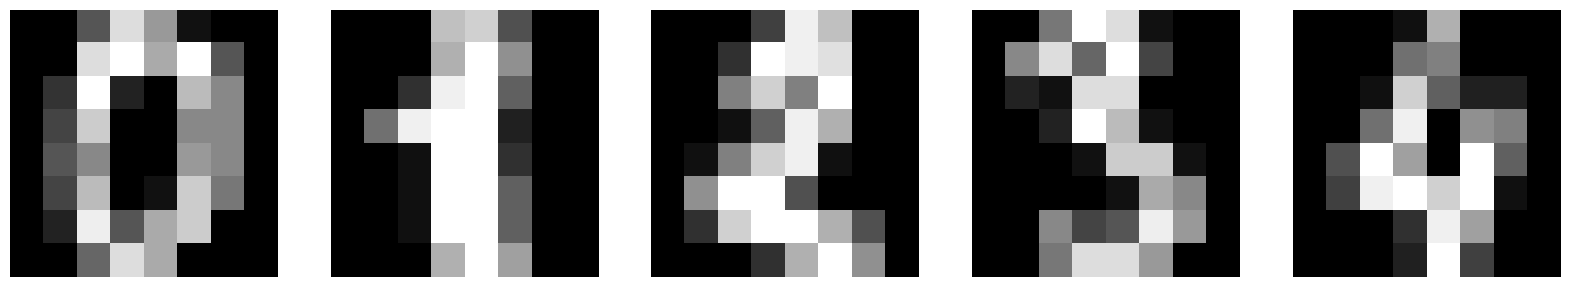

In [3]:
digits = load_digits()
# 1797 images of 8 by 8 pixels, so 64 variables per image
print("Image Data Shape", digits.data.shape)

# Show the first 5 images, without their labels: this is all the information our model gets
plt.figure(figsize=(20, 4))
for index, image in enumerate(digits.data[0:5]):
    plt.subplot(1, 5, index + 1)
    plt.imshow(np.reshape(image, (8, 8)), cmap=plt.cm.gray)
    plt.axis('off')
plt.show()

Our dataset contains 1,797 observations, each with 64 variables: the brightness (from 0 to 16) of each pixel in an 8x8 image. Our goal is to group these observations without using their labels. We hope that the groups the model discovers will correspond to the actual digits.

Here we artificially ignore the labels to simulate unsupervised learning, but this situation is very common in practice: labeling data is often expensive or simply impossible, so true labels are frequently not available.

## 7.3 Model

### 7.3.1 Model

The k-means algorithm has one important hyperparameter, k: the number of clusters we want to find. The algorithm works as follows:

1. Choose k points in the feature space as initial cluster centers
2. Assign each observation to the nearest cluster center
3. Recalculate each cluster center as the mean of all observations assigned to it
4. Repeat steps 2 and 3 until the cluster assignments no longer change

More formally, the algorithm follows an *Expectation-Maximization* approach:

1. Initialize the cluster centers
2. Repeat until convergence:
   - E-step: assign each point to the nearest cluster center
   - M-step: move each cluster center to the mean of the points assigned to it

This process is visualized in the diagram below:

![The E-step and M-step of k-means, repeated until convergence (figure from the Python Data Science Handbook by Jake VanderPlas)](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/figures/05.11-expectation-maximization.png?raw=1)

**Note**: the initial centers matter. With an unlucky start, the algorithm can get stuck in a poor solution. That's why scikit-learn picks the starting centers in a smart way (*k-means++*: the initial centers are spread out over the data) and can run the whole algorithm several times, keeping the best result.

### Demystifying the Math Behind k-Means

While the algorithm might seem simple, there's some interesting mathematics behind it. Let's break it down:

1. **Distance Calculation**
   - We use the Euclidean distance between two points $p$ and $q$ in $n$-dimensional space: $d(p, q) = \sqrt{\sum_{i=1}^n (p_i - q_i)^2}$
   - This is simply the straight-line distance between the two points

2. **Centroid Calculation**
   - For each cluster $j$: $\mu_j = \frac{1}{|C_j|} \sum_{i \in C_j} x_i$
   - $C_j$ is the set of points in cluster $j$ and $|C_j|$ is the number of points in it
   - $x_i$ are the individual data points
   - In words: the center (or *centroid*) of a cluster is the average of all its points

3. **Objective Function**
   - k-means tries to minimize: $J = \sum_{j=1}^k \sum_{i \in C_j} ||x_i - \mu_j||^2$
   - This is called the **inertia** or *within-cluster sum of squares*: the total squared distance between every point and the center of its cluster
   - For a fixed k, a lower inertia means more compact clusters

Don't worry if the math looks intimidating: the key intuition is that we're:
1. Finding the nearest center for each point
2. Moving each center to the middle of its assigned points
3. Repeating until things stabilize

Let's see this in practice on our toy dataset with 4 groups:

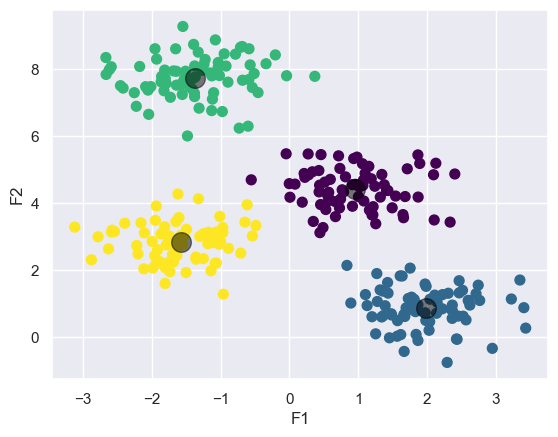

In [4]:
# Fit k-means with k=4 and get the cluster of every point
kmeans_blobs = KMeans(n_clusters=4, n_init=10, random_state=0)
blob_clusters = kmeans_blobs.fit_predict(X)

# Color each point by its cluster and mark the cluster centers with a black dot
plt.scatter(X[:, 0], X[:, 1], c=blob_clusters, s=50, cmap='viridis')
centers = kmeans_blobs.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)
plt.xlabel('F1')
plt.ylabel('F2')
plt.show()

Without seeing a single label, k-means has found the 4 groups we spotted by eye. Each center (black dot) lies in the middle of its group.

### 7.3.2 Model Estimation

Now let's apply k-means to the digits. Luckily, scikit-learn makes this really easy. We ask for 10 clusters, since we expect one cluster per digit:

- `n_init=10`: run the algorithm 10 times, each time with different starting centers, and keep the result with the lowest inertia
- `random_state=0`: makes the random starting centers reproducible, so you get the same results every time you run the notebook

In [5]:
kmeans = KMeans(n_clusters=10, n_init=10, random_state=0)
# fit_predict() finds the clusters and returns the cluster number (0-9) of every image
clusters = kmeans.fit_predict(digits.data)
kmeans.cluster_centers_.shape

(10, 64)

The result is 10 cluster centers with 64 values each. Every center is the *average image* of all the images in its cluster. When a new image comes in, it is assigned to the cluster with the nearest center. Since each center is an 8x8 image, we can visualize them:

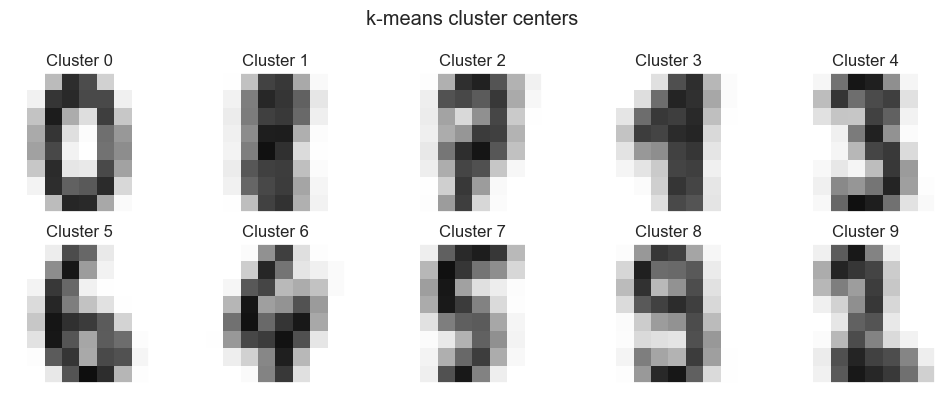

In [6]:
fig, ax = plt.subplots(2, 5, figsize=(10, 4))
centers = kmeans.cluster_centers_.reshape(10, 8, 8)
for i, (axi, center) in enumerate(zip(ax.flat, centers)):
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary, vmin=0, vmax=16)
    axi.set_title('Cluster %i' % i)
    axi.set_xticks([])
    axi.set_yticks([])
fig.suptitle('k-means cluster centers')
plt.tight_layout()
plt.show()

##### Question 1: Look at the cluster centers visualized above. What patterns do you observe? Are some digits easier to recognize than others? Which ones seem to be more ambiguous?

Remarkably, even without using any labels, k-means has found clusters whose centers look like real digits:

- **Clearly visible**: the centers of clusters 0, 2, 4, 5, 6, 7 and 9 are easy to read as a **0**, **7**, **3**, **6**, **4**, **5** and **2**. These digits have a distinctive shape that differs from all other digits.
- **Ambiguous**: clusters 1 and 3 both look like a **1**, but cluster 1 is much blurrier and wider than cluster 3. Cluster 8 looks like a **9**, but it is also blurry.
- **Missing**: none of the centers looks like an **8**!

**Why does this happen?** k-means only looks at pixel values. A thick or slanted 1 shares many dark pixels with an 8 (both have a vertical stroke through the middle), so these images end up close together and get averaged into one blurry center. The same goes for 9, 8 and 5, which share the loops and curves in the upper half of the image. Because we only allowed 10 clusters and the algorithm spent two of them on different styles of writing a 1, there was no cluster left for the 8s: they are divided over the "1" and "9" clusters. We'll confirm this in the next section.

### 7.3.3 Model Evaluation

In supervised learning, we had clear metrics like accuracy or MSE. In clustering, evaluation is harder: in real applications we don't have the true labels, so there is nothing to compare with. For the digits, however, we *do* have the labels. We didn't use them for training, but we can use them now to check how good our clusters are.

There is one catch: k-means numbers its clusters in an arbitrary order. Cluster 0 is not necessarily the digit 0 (look at cluster 2 above: it looks like a 7). So first, we need to translate each cluster into a digit:

- For each cluster, we look up the most common true digit among its images
- That digit becomes the "predicted" label for every image in the cluster
- Example: if cluster 2 mostly contains 7s, every image in cluster 2 is predicted to be a 7

In [7]:
labels = np.zeros_like(clusters)
for i in range(10):
    # Only select the images that were assigned to cluster i
    mask = (clusters == i)
    # mode() picks the value that occurs the most: the most common digit in this cluster
    labels[mask] = mode(digits.target[mask])[0]
    # bincount() counts how many images of each digit (0-9) the cluster contains
    print('Cluster %i: most common digit %i | digit counts:' % (i, mode(digits.target[mask])[0]),
          np.bincount(digits.target[mask], minlength=10))

Cluster 0: most common digit 0 | digit counts: [176   0   1   0   0   0   1   0   0   0]
Cluster 1: most common digit 1 | digit counts: [  0 100   8   7   2   0   3   2 100   1]
Cluster 2: most common digit 7 | digit counts: [  0   0   3   7  11   0   0 174   5   8]
Cluster 3: most common digit 1 | digit counts: [ 0 54  2  0  3  0  0  2  6 20]
Cluster 4: most common digit 3 | digit counts: [  0   1  13 154   0   2   0   0   2   6]
Cluster 5: most common digit 6 | digit counts: [  0   2   0   0   0   1 177   0   2   0]
Cluster 6: most common digit 4 | digit counts: [  2   0   0   0 165   2   0   0   0   0]
Cluster 7: most common digit 5 | digit counts: [  0   1   0   2   0 136   0   1   4   6]
Cluster 8: most common digit 9 | digit counts: [  0   0   2  13   0  41   0   0  52 139]
Cluster 9: most common digit 2 | digit counts: [  0  24 148   0   0   0   0   0   3   0]


This confirms what we saw in the cluster centers: clusters 1 and 3 are both labeled as a 1, so no cluster is labeled as an 8. Our model will therefore *never* predict an 8.

Look closely at cluster 1: it contains exactly as many 1s as 8s (100 of each). When there is a tie, `mode()` returns the smallest value, so the cluster is labeled as a 1. Most of the other 8s ended up in cluster 8, together with the 9s and some 5s.

Let's calculate the overall accuracy:

In [8]:
accuracy_score(digits.target, labels)

0.7918753478018921

Our model labels about **79%** of all digits correctly, purely based on the structure of the pixel data and without any knowledge of the true labels. That's an impressive result: random guessing would only give 10%. Of course, this score is lower than what our supervised models reached in the previous chapters (for example about 96% for logistic regression and 99% for k-NN), but those models *did* learn from the labels.

The model makes two types of errors:
- **Variation within a digit**: the same digit can be written in very different ways (as we saw with the two clusters for the 1)
- **Similarity between digits**: different digits can look alike, especially at a resolution of only 8x8 pixels

These are challenges that even humans face! To see exactly where the model makes mistakes, let's look at the confusion matrix:

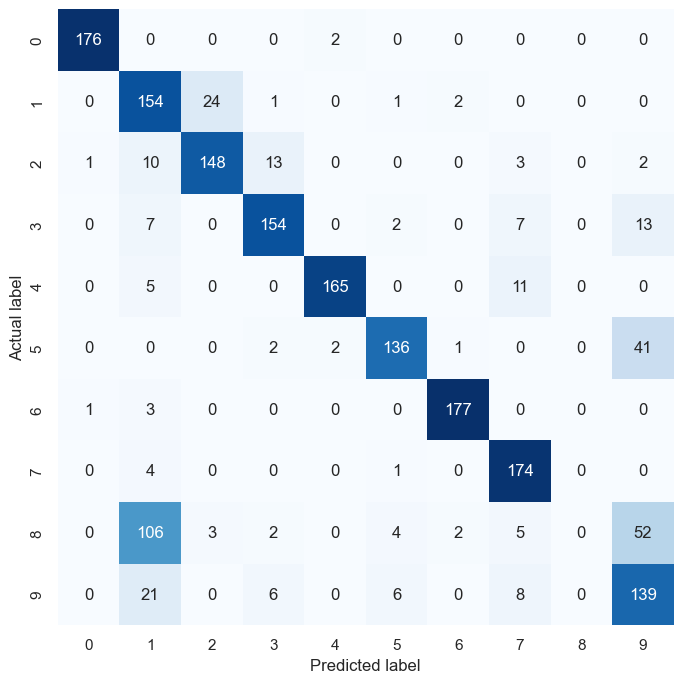

In [9]:
mat = confusion_matrix(digits.target, labels)
plt.figure(figsize=(8, 8))
sns.heatmap(mat, square=True, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=digits.target_names, yticklabels=digits.target_names)
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.show()

##### Question 2: Analyze the confusion matrix above. Which digits are most commonly confused with each other? Can you explain why these particular confusions might occur?

Most digits (0, 1, 2, 3, 4, 6, 7 and 9) are labeled correctly more than 75% of the time. The most common misclassifications are:

- **8 predicted as 1 (106 times) or as 9 (52 times)**: not a single 8 is labeled correctly, because no cluster was assigned to the 8. As we saw in Question 1, thin or slanted 8s look a lot like a thick 1 at this low resolution, while the closed loop at the top of an 8 resembles the loop of a 9.
- **5 predicted as 9 (41 times)**: a 5 and a 9 both have a curve in the upper half and a stroke going down on the right side.
- **1 predicted as 2 (24 times)** and **9 predicted as 1 (21 times)**: some 1s are written with a base line at the bottom, which makes them look like a 2, while some 9s have a very small loop and a long straight stroke, which makes them look like a 1.
- **2 predicted as 3 (13 times)** and **3 predicted as 9 (13 times)**: these digits share curves on their right side.

All of these confusions have the same cause: k-means groups images whose pixels are *close* to each other. It has no idea what a digit is supposed to look like. When two digits share many dark pixels, their images end up close together in the 64-dimensional feature space and can end up in the same cluster.

## 7.4 Choosing the Optimal k

The k-means algorithm requires us to specify the number of clusters (k) as a hyperparameter. In our digits example, it's obvious that we should look for 10 clusters (one for each digit from 0 to 9). Even without access to the labels, we would know to expect 10 distinct groups, or perhaps 11 if there were non-digit images in the dataset.

However, in real-world applications, we often don't have this prior knowledge. Consider Netflix's challenge of categorizing movies by genre: how many distinct genres exist? Is there a clear boundary between action and crime movies? In such cases, there is no predetermined number of clusters, yet we still need to choose a value for k.

Earlier, we compared our clusters to the true labels, but in real applications this usually isn't possible. Instead, we can measure how *compact* the clusters are using the **inertia** (the within-cluster sum of squares from section 7.3.1).

There is a catch, though: the inertia always decreases when we add more clusters. With as many clusters as observations, every point is its own center and the inertia drops to 0, but such a model is useless. So we don't look for the *lowest* inertia. Instead, we fit the model for different values of k and look for the point where adding an extra cluster stops making a big difference. On a plot, this point looks like a bend in an arm, which is why this technique is called the **Elbow Method**.

Let's first try it on our toy dataset, where we know that the answer is 4:

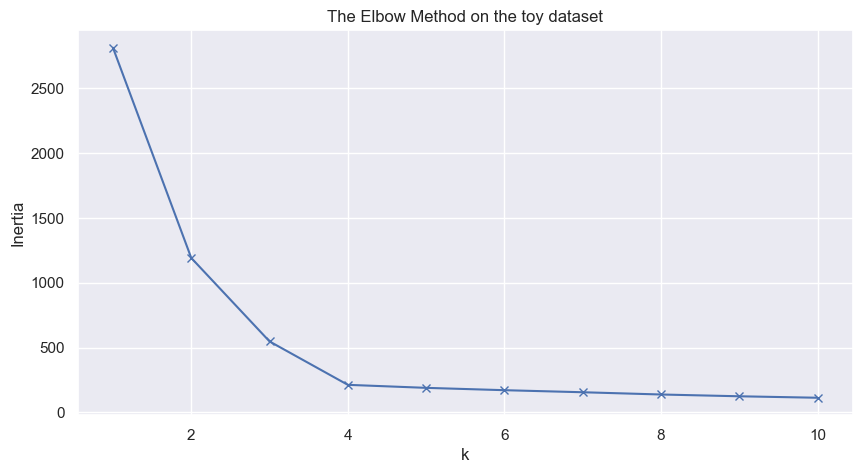

In [10]:
inertias_blobs = []
K_blobs = range(1, 11)
for k in K_blobs:
    model = KMeans(n_clusters=k, n_init=10, random_state=0)
    model.fit(X)
    inertias_blobs.append(model.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(K_blobs, inertias_blobs, 'bx-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('The Elbow Method on the toy dataset')
plt.show()

Here the elbow is very clear: the inertia drops steeply until k = 4 (from about 2,800 to about 200) and barely decreases after that. Adding a fifth cluster would only split one of the 4 groups in two, which hardly makes the clusters more compact. So the Elbow Method correctly suggests k = 4.

Now let's do the same for the digits, for k going from 1 to 30:

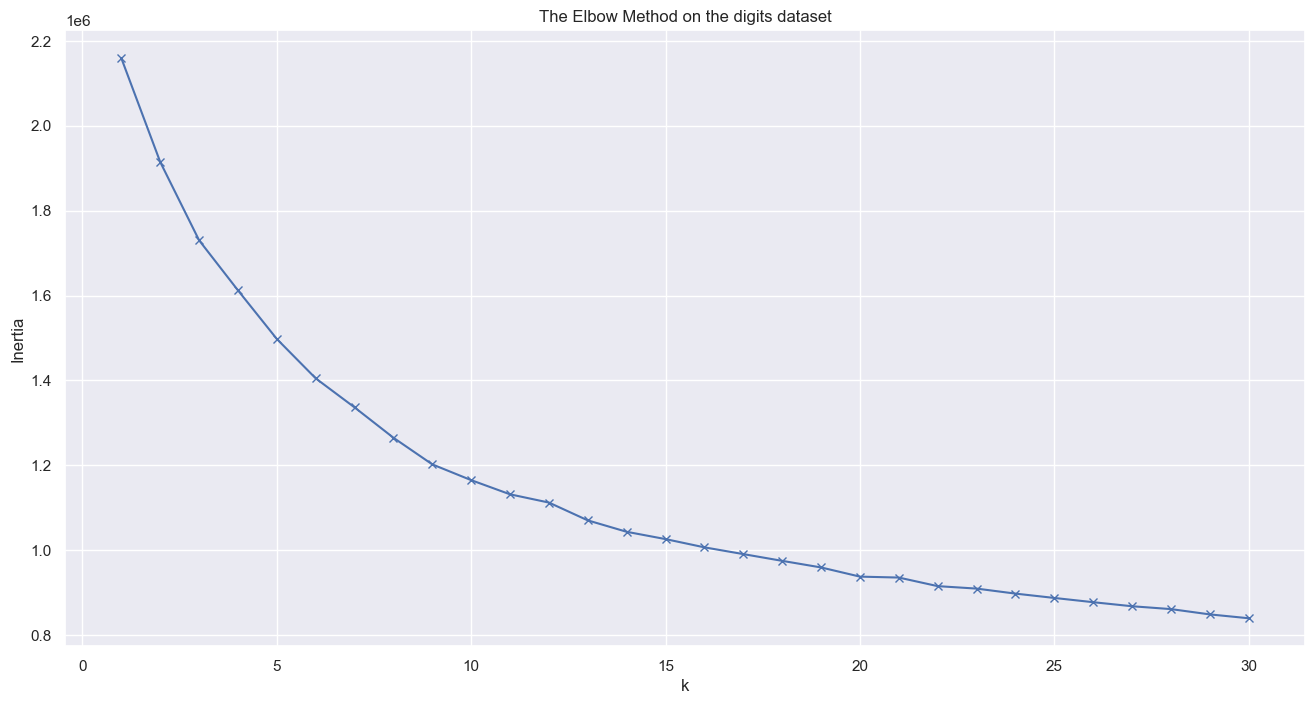

In [11]:
inertias = []
K = range(1, 31)
for k in K:
    model = KMeans(n_clusters=k, n_init=10, random_state=0)
    model.fit(digits.data)
    inertias.append(model.inertia_)

plt.figure(figsize=(16, 8))
plt.plot(K, inertias, 'bx-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('The Elbow Method on the digits dataset')
plt.show()

##### Question 3: What is the optimal number of clusters according to the elbow method? How does this compare to what we know about the digits dataset? Explain your reasoning.

Unlike the toy dataset, the digits do **not** show a clear elbow. The inertia decreases quickly at first (from about 2.16 million at k = 1 to about 1.17 million at k = 10), but it keeps decreasing steadily after that (to about 0.84 million at k = 30). The curve bends gradually instead of at one sharp point, so we can't read an optimal k from this plot. At most, we could say that the curve starts flattening somewhere between k = 8 and k = 12.

From our prior knowledge, we know that k = 10 is the "right" answer. The Elbow Method doesn't contradict this, but it doesn't clearly confirm it either. This is because the digit clusters are not nicely separated like our toy blobs:
- Some digits overlap (as we saw with the 1, 8 and 9), so merging or splitting them doesn't cause a sudden jump in the inertia
- Some digits are written in several different styles (like the 1), so splitting them into extra clusters keeps reducing the inertia

**Lesson learned**: the Elbow Method is a useful heuristic, but on real data the elbow is often hard to see. In that case, we should combine it with other metrics and with domain knowledge about the problem.

##### Going further: the silhouette score

Another popular way to choose k is the **silhouette score**. For every point, it compares the average distance to the other points in its own cluster with the average distance to the points in the nearest *other* cluster. The score ranges from -1 to 1:
- Close to **1**: the point is much closer to its own cluster than to any other cluster (well-separated clusters)
- Close to **0**: the point lies on the border between two clusters (overlapping clusters)
- **Negative**: the point is probably in the wrong cluster

Unlike the inertia, the silhouette score doesn't automatically improve when k increases, so we can simply look for the **highest** score:

Best k: 9 with a silhouette score of 0.189


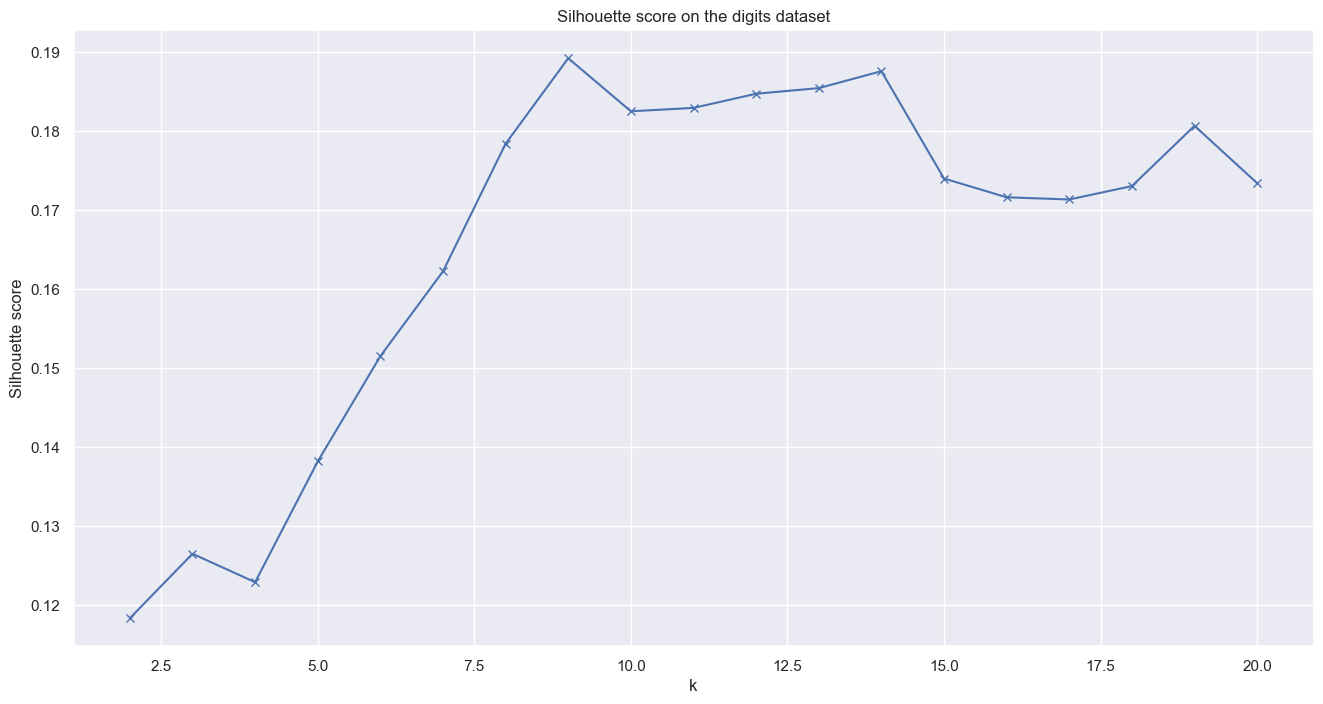

In [12]:
silhouettes = []
K_silhouette = range(2, 21)   # the silhouette score needs at least 2 clusters
for k in K_silhouette:
    model = KMeans(n_clusters=k, n_init=10, random_state=0)
    silhouettes.append(silhouette_score(digits.data, model.fit_predict(digits.data)))

print('Best k:', K_silhouette[np.argmax(silhouettes)], 'with a silhouette score of %.3f' % max(silhouettes))

plt.figure(figsize=(16, 8))
plt.plot(K_silhouette, silhouettes, 'bx-')
plt.xlabel('k')
plt.ylabel('Silhouette score')
plt.title('Silhouette score on the digits dataset')
plt.show()

The silhouette score increases until about k = 9 (0.189) and then stays almost flat up to k = 14, before dropping. So it points to a range of 9 to 14 clusters, which agrees nicely with our prior knowledge of 10 digits. However, the scores themselves are low (below 0.2): many images lie close to the border between two clusters. This confirms what we saw in the confusion matrix: the digit clusters overlap quite a lot.

## 7.5 Model Validation

##### Question 4: Implement a train-test split evaluation of the k-means model. Does the model perform similarly on test data as it does on training data? What might explain any differences or similarities?

**Approach**: the test images should play no role at all while building the model:
1. Fit k-means on the training images only
2. Translate each cluster into a digit using the **training** labels only
3. Assign each test image to its nearest cluster center with `predict()` and translate that cluster into a digit
4. Compare the training accuracy with the test accuracy

Digit of each cluster (cluster 0 to 9): [7 8 1 4 6 2 5 0 3 1]
Training accuracy: 0.797
Test accuracy:     0.784


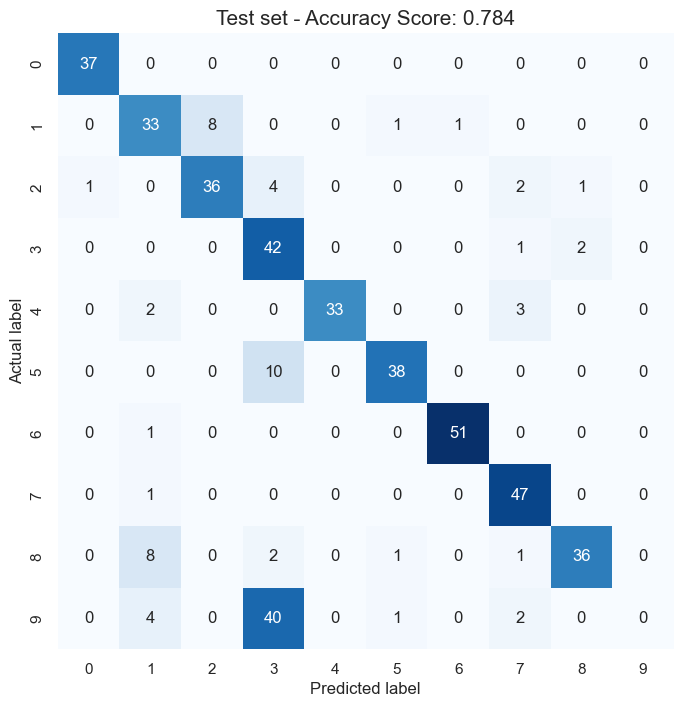

In [13]:
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.25, random_state=0)

# 1. Fit k-means on the training images only (still without using any labels)
kmeans_train = KMeans(n_clusters=10, n_init=10, random_state=0)
train_clusters = kmeans_train.fit_predict(X_train)

# 2. Translate each cluster into a digit, using the training labels only
cluster_to_digit = np.zeros(10, dtype=int)
for i in range(10):
    cluster_to_digit[i] = mode(y_train[train_clusters == i])[0]
print('Digit of each cluster (cluster 0 to 9):', cluster_to_digit)

# 3. Assign each image to its nearest cluster center and look up the digit of that cluster
train_predictions = cluster_to_digit[train_clusters]
test_predictions = cluster_to_digit[kmeans_train.predict(X_test)]

# 4. Compare training and test accuracy
train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)
print('Training accuracy: %.3f' % train_accuracy)
print('Test accuracy:     %.3f' % test_accuracy)

cm = confusion_matrix(y_test, test_predictions)
plt.figure(figsize=(8, 8))
sns.heatmap(cm, square=True, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=digits.target_names, yticklabels=digits.target_names)
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Test set - Accuracy Score: %.3f' % test_accuracy, size=15)
plt.show()

The model performs almost the same on both sets: a training accuracy of about **0.797** and a test accuracy of about **0.784**. The model generalizes well to images it has never seen. There are two reasons for this:

- **k-means is a simple model**: it only learns 10 cluster centers, and each center is an *average* over more than a hundred images. Averages hardly change when a few images are added or removed, so the model can't memorize individual training images. Compare this to k-NN with k = 1 from the previous chapter, which reached a perfect training accuracy by memorizing every training image.
- **The labels are only used to name the clusters**: the clusters themselves are built from the pixel structure, which is the same in the training and test set.

Notice that the errors are also similar to before. Again, two clusters are labeled as a 1, but this time no cluster is labeled as a 9, so 40 of the 47 test 9s are predicted as a 3. The weakness of the model is not overfitting, but the fact that some digits overlap too much to get a cluster of their own. More training data wouldn't fix this. That is the real limitation of using k-means as a classifier.

## 7.6 Key Takeaways

### Limitations of k-Means

It's important to understand what k-means can and cannot do:

1. **Assumptions About the Data**
   - Clusters are roughly spherical (round)
   - Clusters are of similar size
   - Every data point belongs to exactly one cluster

2. **Potential Challenges**
   - The result depends on the initial centers, and the algorithm may get stuck in a poor solution (use `n_init` to run it several times)
   - k-means struggles with:
     * Elongated clusters
     * Irregular shapes
     * Clusters of very different sizes

3. **When to Use k-Means**
   - ✅ Well-separated groups
   - ✅ Clusters of similar size
   - ✅ Roughly spherical clusters
   - ❌ Complex shapes
   - ❌ Highly uneven cluster sizes
   - ❌ When you need a hierarchy of clusters (see the next chapter on hierarchical clustering)

### Best Practices

1. **Algorithm Selection**
   - Use k-means when:
     * You know approximately how many clusters to expect
     * Your data forms roughly spherical clusters
     * You need a simple, fast clustering method

2. **Preprocessing Steps**
   - Scale your features when they are measured on different scales: k-means is based on distances, so a feature with large values would dominate. Our digit data didn't need scaling, because all 64 pixels are measured on the same scale (0 to 16)
   - Remove outliers if possible: a single extreme point can pull a cluster center away from its group
   - Consider dimensionality reduction for high-dimensional data (see the chapter on dimensionality reduction)

3. **Model Validation**
   - Use multiple random initializations (`n_init` parameter)
   - Try different values of k
   - When possible, validate against known labels
   - Use the silhouette score when there are no labels

4. **Common Pitfalls to Avoid**
   - Don't assume that all data can be clustered
   - Don't rely solely on the Elbow Method
   - Don't forget to scale your features
   - Don't ignore domain knowledge when choosing k

Remember: k-means is just one tool in the clustering toolbox. For complex real-world problems, you might need alternatives such as hierarchical clustering, DBSCAN or Gaussian mixture models.